# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.Fm Linear Regression Notebook
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 17th October 2026*

---

This notebook explores a linear regression question using Last.fm scrobbles merged with Spotify track features:

- Does the average release year of music I scrobble change from week to week?


Every scrobble is joined to its track's Spotify features, using the same cleaning functions as the collection notebook, with times converted to Dublin local time


### Load and prepare the scrobble data

Load the raw scrobbles and the merged track features, clean the artist and track names so the two files can be joined, and keep only plays that matched with a Spotify track. Dates are converted to Dublin time so weeks line up with my actual day

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np
from data_clean import clean_text, clean_artist
from sklearn.metrics import mean_absolute_error

audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']
tags = ['release_year', 'popularity', 'artist_popularity', 'explicit']

plays = pd.read_csv('../datasets/scrobbles.csv')
scrobbles = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

# dublin time
local = pd.to_datetime(plays['date']).dt.tz_localize('UTC').dt.tz_convert('Europe/Dublin')
plays['local_time'] = local.dt.tz_localize(None)
plays['local_date'] = plays['local_time'].dt.normalize()

plays['clean_track'] = clean_text(plays['song'])
plays['clean_artist'] = clean_artist(plays['artist'])

# one row per unique track with its Spotify features
scrobbles_unique = scrobbles.drop_duplicates(['clean_artist', 'clean_track']).copy()

# every play that could be matched to Spotify features
plays_feat = plays.merge(scrobbles_unique[['clean_artist', 'clean_track'] + audio + tags],
                         on=['clean_artist', 'clean_track'], how='inner')

print(f"All scrobbles:                  {len(plays):,}")
print(f"Scrobbles matched to Spotify:   {len(plays_feat):,}  ({len(plays_feat) / len(plays):.1%} of plays)")
print(f"Unique tracks:                  {len(scrobbles_unique):,}  ")
print(f"Listening window:               {plays['local_date'].min().date()} to {plays['local_date'].max().date()}")

All scrobbles:                  17,999
Scrobbles matched to Spotify:   14,629  (81.3% of plays)
Unique tracks:                  1,838  
Listening window:               2025-11-18 to 2026-10-14


____________________________________________________________________________________________________________________________________________________________________________________________________________________________________
Using the [handbook](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.06-Linear-Regression.ipynb) example shown in class which predicts bicycle trips across a Seattle bridge from the day of the week, holidays, daylight hours and a trend term. The same formula fits my listening: **how many songs do I scrobble per day, and what drives it?**

Additional thought was given to the following: 

- Days with no listening at all are still real days, so they're filled in with 0
- Days end at midnight Dublin time
- Hours of daylight use Dublin's latitude (53.35 N) 

In [2]:
daily = plays.groupby('local_date').size().rename('scrobbles').to_frame()
# any missing days are filled with 0
daily = daily.reindex(fill_value=0)
daily.index.name = 'date'
print(f"Days analysed: {len(daily)}, days with zero scrobbles: {(daily['scrobbles'] == 0).sum()}")

# day of week cols
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for i in range(7):
    daily[days[i]] = (daily.index.dayofweek == i).astype(float)

# irish public holidays (hard-coded so the notebook needs no extra package)
holidays = pd.to_datetime([
    '2025-01-01', '2025-02-03', '2025-03-17', '2025-04-21', '2025-05-05', '2025-06-02',
    '2025-08-04', '2025-10-27', '2025-12-25', '2025-12-26',
    '2026-01-01', '2026-02-02', '2026-03-17', '2026-04-06', '2026-05-04', '2026-06-01',
    '2026-08-03', '2026-10-26', '2026-12-25', '2026-12-26'])
daily['holiday'] = daily.index.isin(holidays).astype(float)

# hours of daylight for dublin's latitude
def hours_of_daylight(dates, axis=23.44, latitude=53.35):
    """Hours of daylight for a DatetimeIndex (Handbook formula, Dublin latitude)."""
    d = (dates - pd.Timestamp(2000, 12, 21)).days.to_numpy()
    m = 1.0 - np.tan(np.radians(latitude)) * np.tan(np.radians(axis) * np.cos(d * 2 * np.pi / 365.25))
    return 24.0 * np.degrees(np.arccos(1 - np.clip(m, 0, 2))) / 180.0

daily['daylight'] = hours_of_daylight(daily.index)
daily['annual'] = (daily.index - daily.index[0]).days / 365.25
daily.head()

Days analysed: 311, days with zero scrobbles: 0


,scrobbles,Mon,Tue,Wed,Thu,Fri,Sat,Sun,holiday,daylight,annual
date,,,,,,,,,,,
2025-11-18,183,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,8.162392,0.000000
2025-11-19,103,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,8.112555,0.002738
2025-11-20,135,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,8.063778,0.005476
2025-11-21,61,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,8.016092,0.008214
2025-11-22,122,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,7.969531,0.010951


With the data in order, fit a linear regression. Like in the Handbook, `fit_intercept=False` because the seven day-of-week flags already act as seven intercepts (one per weekday). 

The `prev7`column is the average of the previous seven days, shifted so that today is never included. Lets us know if a busy week tends to be followed by another busy week 

The plot shows actual daily counts and the model's predictions, which are also using the previouss seven days average

Train R-squared:  0.262
Test R-squared:   -1.237
Test MAE:         42.1 scrobbles
Baseline MAE:     28.5 scrobbles
Mon         37.5
Tue         52.2
Wed         55.6
Thu         39.1
Fri         40.0
Sat         42.2
Sun         32.9
holiday    -10.9
daylight    -4.3
annual      90.4
prev7        0.6
dtype: float64


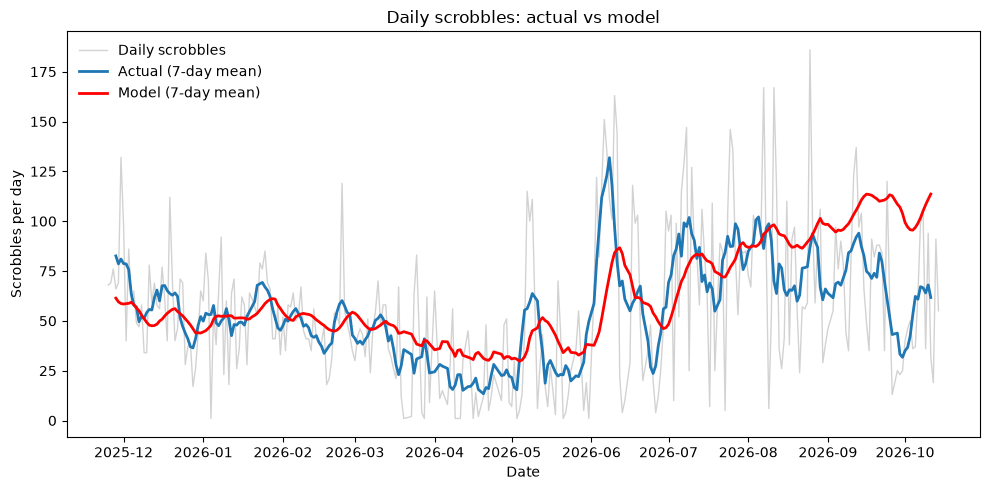

In [3]:
# fit on the first 80% of days (split by date, not randomly), then plot actual vs predicted (
daily['prev7'] = daily['scrobbles'].shift(1).rolling(7).mean()
data = daily.dropna().copy()

cols = days + ['holiday', 'daylight', 'annual', 'prev7']

# split by date, not randomly, so the model predicts days it hasn't seen (train_test_split from Hyperparameters-and-Model-Validation.ipynb would shuffle them)
# 0.8 = 80%
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]


model_B = LinearRegression(fit_intercept=False).fit(train[cols], train['scrobbles'])
data['predicted'] = model_B.predict(data[cols])

baseline = train['scrobbles'].mean()

print(f"Train R-squared:  {model_B.score(train[cols], train['scrobbles']):.3f}")
print(f"Test R-squared:   {model_B.score(test[cols], test['scrobbles']):.3f}")
print(f"Test MAE:         {mean_absolute_error(test['scrobbles'], model_B.predict(test[cols])):.1f} scrobbles")
print(f"Baseline MAE:     {mean_absolute_error(test['scrobbles'], [baseline] * len(test)):.1f} scrobbles")
print(pd.Series(model_B.coef_, index=cols).round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(data.index, data['scrobbles'], color="grey", alpha=0.35, lw=1, label='Daily scrobbles')
ax.plot(data.index, data['scrobbles'].rolling(7, center=True).mean(), lw=2, label='Actual (7-day mean)')
ax.plot(data.index, data['predicted'].rolling(7, center=True).mean(), color="red", lw=2, label='Model (7-day mean)')
ax.set(title='Daily scrobbles: actual vs model', xlabel='Date', ylabel='Scrobbles per day')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

The data and the model predictions don't line up exactly. My listening comes in bursts, tied to whatever I'm doing at the time, and a calendar can't know that. Examples of what may have impacted the trends: internship, college work

### Result for Daily Model

I trained the model on the first 80% of days and tested it on the last 20%. On the training days it explains about 26% of the ups and downs in my scrobbles (R-squared 0.26). On the days it hadn't seen it did worse than just guessing the average day every time (test R-squared -1.24, and it was off by 42 scrobbles on average compared with 28.5 for the guess).

Some patterns do show up in the coefficients. Tuesday and Wednesday are my biggest days (about 52 and 56 scrobbles) and Sunday and Monday are the smallest (about 33 and 38). The `annual` term is big (90 per year), which makes sense because I listened to more as the year went on. `prev7` is positive (0.6), so a busy week usually means a busy day next. Holidays (-11) and daylight (-4 per hour) don't change much

The model isn't good at predicting new days because the data is just from the last year. In the handbook's bike example the same features worked well, because people commute on a regular schedule and my listening doesn't follow one

__________________

This section examines how well does a song's energy predict its overall loudness?

To prevent skewing the results with duplicate tracks, the dataset was filtered to include on unique tracks (2,041 total)

Slope (dB per 1.0 of energy):  14.732
Intercept:                     -18.3
R-squared:                     0.6029
Tracks analysed:               2041


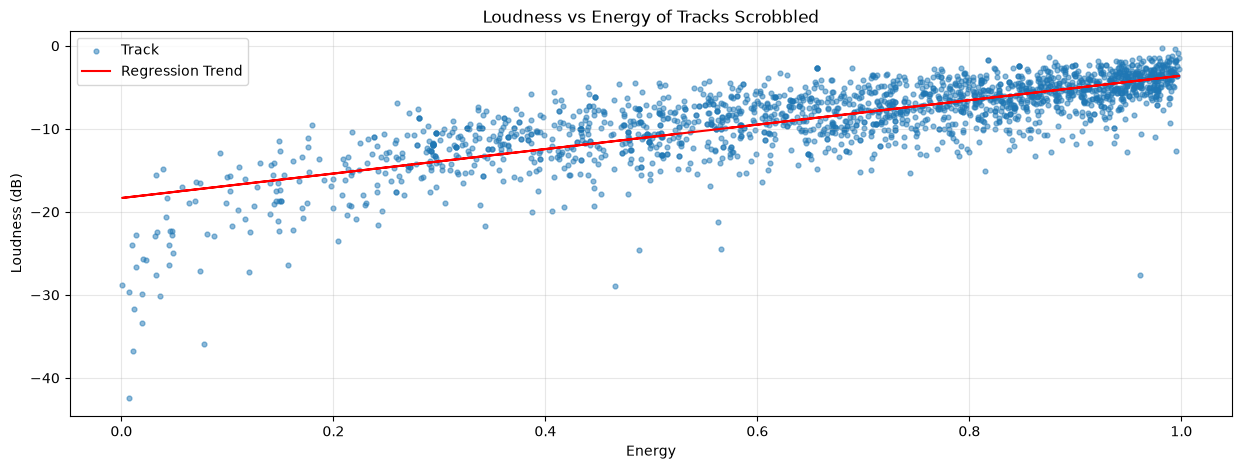

In [4]:
# one row per track so tracks I replayed a lot don't weight the line
tracks_feat = plays_feat.drop_duplicates(subset='song').dropna(subset=['energy', 'loudness'])

X = tracks_feat[['energy']]
y = tracks_feat['loudness']

# referenced Linear-Regression.ipynb:
# fit the estimator, then use predict() and score() for model evaluation
model = LinearRegression()
model.fit(X, y)

print(f"Slope (dB per 1.0 of energy):  {model.coef_[0]:.3f}")
print(f"Intercept:                     {model.intercept_:.1f}")
print(f"R-squared:                     {model.score(X, y):.4f}")
print(f"Tracks analysed:               {len(tracks_feat)}")

plt.figure(figsize=(15, 5))
plt.scatter(X['energy'], y, s=12, alpha=0.5, label='Track')
plt.plot(X['energy'], model.predict(X), color='red', label='Regression Trend')
plt.title('Loudness vs Energy of Tracks Scrobbled')
plt.xlabel('Energy')
plt.ylabel('Loudness (dB)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

There's a strong positive relationship between a track's energy and its loudness, with the baseline loudness starting at -18.3 dB and increasing by 14.73 dB for every 1.0 unit increase in energy

The straight line explains 60.29% of the variance in loudness, so it fits for more than half of the data

The scatter plot reveals a flattening effect as energy approaches 1.0, alongside a handful of extreme quiet outliers that sit far below the main data cluster.

Because the linear trend line didn't fit the curve at the high end of the spectrum of energy, a polynomial with a degree of 3 model was introduced to capture this 

Linear R-squared:      0.6029
Polynomial R-squared:  0.6584


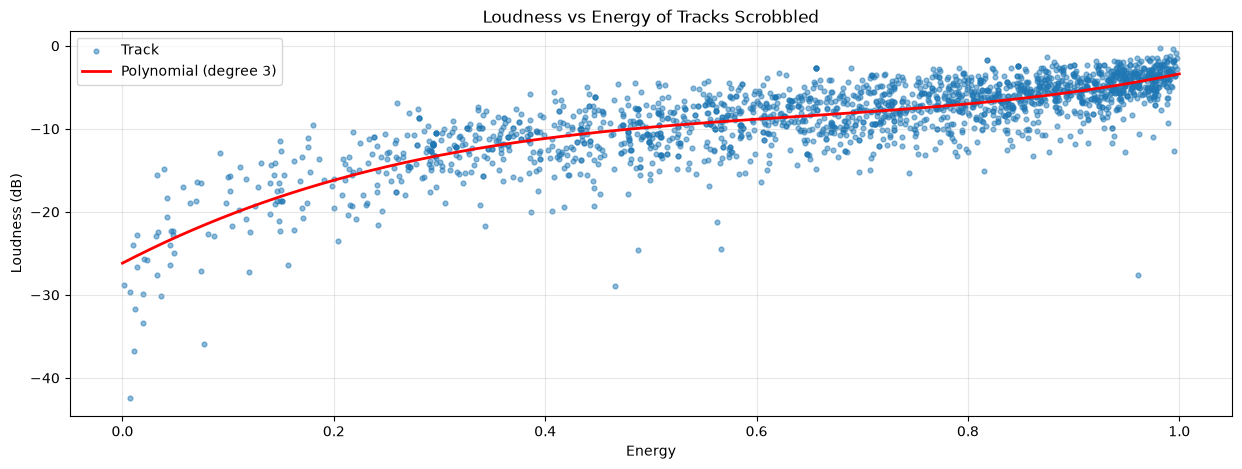

In [5]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

poly_model = make_pipeline(PolynomialFeatures(3), LinearRegression())
poly_model.fit(X, y)

print(f"Linear R-squared:      {model.score(X, y):.4f}")
print(f"Polynomial R-squared:  {poly_model.score(X, y):.4f}")

# evenly spaced energy values so the curve is drawn smoothly
x_grid = pd.DataFrame({'energy': np.linspace(0, 1, 300)})

plt.figure(figsize=(15, 5))
plt.scatter(X['energy'], y, s=12, alpha=0.5, label='Track')
plt.plot(x_grid['energy'], poly_model.predict(x_grid), color='red', linewidth=2, label='Polynomial (degree 3)')
plt.title('Loudness vs Energy of Tracks Scrobbled')
plt.xlabel('Energy')
plt.ylabel('Loudness (dB)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Transforming the data into a cubic polynomial yields a 5.5% increase in predictive power 

The curved red line accurately traces the plateauing loudness of songs with the maximum possible energy

The curve still fails to capture the low lodness outliers at the bottom left of the plot